# 50-image end-to-end POC (Proof of Concept)

In [3]:
from pathlib import Path
import random
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

In [4]:
dataset_root = Path.cwd().parent / "data" / "raw" / "bdd100k"

train_dir = dataset_root / "train" / "images"
val_dir = dataset_root / "val" / "images"
test_dir = dataset_root / "test"

poc_dir = Path.cwd().parent / "data" / "poc"

random.seed(42)

In [5]:
annotation_file = next(
    (dataset_root / "train" / "annotations").glob("*.json")
)

with open(annotation_file, "r") as f:
    train_annotations = json.load(f)

### Hypothesis: Larger vehicle bounding boxes are more likely to contain visible licence plates.

#### We can calculate the largest vehicle bounding box and the number of vehicles present in each image.

In [6]:
vehicle_categories = {"car", "truck", "bus", "motor"}

records = []

for record in train_annotations:

    vehicle_areas = []

    for obj in record.get("labels", []):

        if obj["category"] not in vehicle_categories:
            continue

        if "box2d" not in obj:
            continue

        box = obj["box2d"]

        width = box["x2"] - box["x1"]
        height = box["y2"] - box["y1"]

        if width > 0 and height > 0:
            vehicle_areas.append(width * height)

    records.append({
        "image_id": record["name"],
        "vehicle_count": len(vehicle_areas),
        "max_vehicle_area": max(vehicle_areas, default=0),
        "timeofday": record["attributes"].get("timeofday"),
        "weather": record["attributes"].get("weather"),
        "scene": record["attributes"].get("scene")
    })

df = pd.DataFrame(records)

df.head()

,image_id,vehicle_count,max_vehicle_area,timeofday,weather,scene
0,0000f77c-6257be58.jpg,2,88514.384906,daytime,clear,city street
1,0000f77c-62c2a288.jpg,0,0.000000,dawn/dusk,clear,highway
2,0000f77c-cb820c98.jpg,7,34049.453081,dawn/dusk,clear,residential
3,0001542f-5ce3cf52.jpg,10,2539.360018,night,clear,city street
4,0001542f-7c670be8.jpg,3,2136.416194,night,clear,highway


In [7]:
df["max_vehicle_area"].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]
)

count     69863.000000
mean      61699.449055
std       67290.945540
min           0.000000
25%       12909.054819
50%       38928.130603
75%       89080.862924
90%      147714.958270
95%      194453.555988
max      828772.182217
Name: max_vehicle_area, dtype: float64

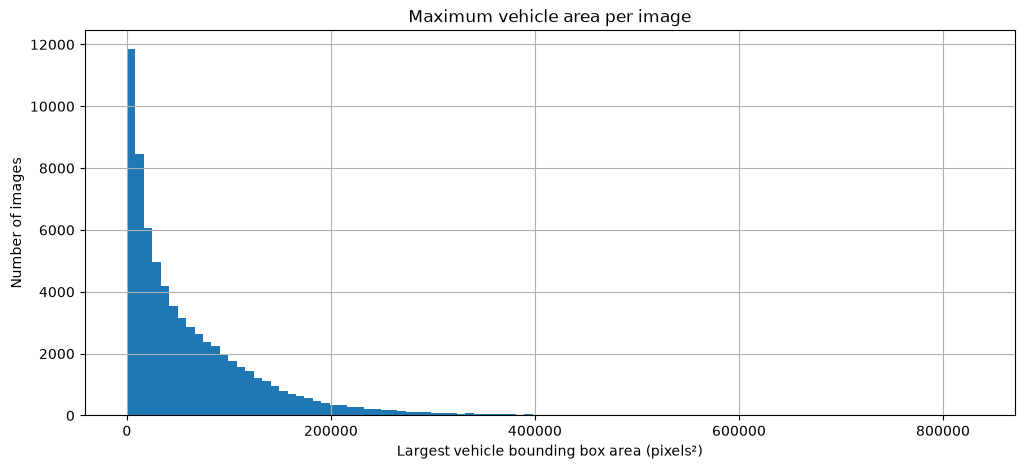

In [8]:
df.loc[
    df["max_vehicle_area"] > 0,
    "max_vehicle_area"
].hist(bins=100, figsize=(12, 5))

plt.xlabel("Largest vehicle bounding box area (pixels²)")
plt.ylabel("Number of images")
plt.title("Maximum vehicle area per image")
plt.show()

In [9]:
# This helps us determine what constitutes a small, medium or large vehicle in our actual dataset rather than choosing arbitrary thresholds.

In [10]:
candidate_groups = [
    df[df["max_vehicle_area"].between(30_000, 200_000)]
        .sample(300, random_state=42),

    df[df["max_vehicle_area"].between(1_000, 29_999)]
        .sample(100, random_state=42),

    df[df["max_vehicle_area"] > 200_000]
        .sample(50, random_state=42),

    df[df["vehicle_count"] == 0]
        .sample(50, random_state=42)
]

candidates = (
    pd.concat(candidate_groups)
    .drop_duplicates(subset="image_id")
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)

print("Candidate images:", len(candidates))

Candidate images: 500


In [11]:
%pip install ipywidgets

Note: you may need to restart the kernel to use updated packages.


In [9]:
import ipywidgets as widgets
from IPython.display import display

targets = {
    "Clear": 15,
    "Multiple": 5,
    "Small": 5,
    "Difficult": 7,
    "Negative": 3
}

current_idx = 0

selected = {}
rejected = set()

image_widget = widgets.Image(
    format="jpeg",
    width=1100
)

status = widgets.HTML()
progress = widgets.HTML()

prev_btn = widgets.Button(description="Previous")
next_btn = widgets.Button(description="Next")

reject_btn = widgets.Button(
    description="Reject",
    button_style="danger"
)

undo_btn = widgets.Button(description="Unassign")

In [10]:
category_buttons = {
    category: widgets.Button(
        description=category,
        button_style="success",
        layout=widgets.Layout(width="160px")
    )
    for category in targets
}

In [11]:
def show_current_image():

    row = candidates.iloc[current_idx]
    filename = row["image_id"]

    image_widget.value = (train_dir / filename).read_bytes()

    counts = {
        category: list(selected.values()).count(category)
        for category in targets
    }

    decision = selected.get(
        filename,
        "Rejected" if filename in rejected else "Unreviewed"
    )

    status.value = (
        f"<b>Image:</b> {current_idx + 1}/{len(candidates)} | "
        f"<b>Selected:</b> {len(selected)}/35 | "
        f"<b>Rejected:</b> {len(rejected)} | "
        f"<b>Status:</b> {decision}<br>"
        f"<b>Filename:</b> {filename}<br>"
        f"<b>Time:</b> {row['timeofday']} | "
        f"<b>Weather:</b> {row['weather']} | "
        f"<b>Vehicles:</b> {row['vehicle_count']} | "
        f"<b>Max vehicle area:</b> {row['max_vehicle_area']:.0f}"
    )

    progress.value = " &nbsp; | &nbsp; ".join(
        f"<b>{category}:</b> {counts[category]}/{target}"
        for category, target in targets.items()
    )

    for category, button in category_buttons.items():

        count = counts[category]
        target = targets[category]

        button.description = f"{category} ({count}/{target})"

        button.disabled = (
            count >= target
            and selected.get(filename) != category
        )

    prev_btn.disabled = current_idx == 0
    next_btn.disabled = current_idx == len(candidates) - 1

In [14]:
def next_image(button=None):
    global current_idx

    current_idx = min(
        current_idx + 1,
        len(candidates) - 1
    )

    show_current_image()


def previous_image(button=None):
    global current_idx

    current_idx = max(current_idx - 1, 0)

    show_current_image()

def assign_category(category):

    filename = candidates.iloc[current_idx]["image_id"]

    count = list(selected.values()).count(category)

    if count >= targets[category] and selected.get(filename) != category:
        return

    selected[filename] = category
    rejected.discard(filename)

    save_selection()
    next_image()
def reject_image(button=None):

    filename = candidates.iloc[current_idx]["image_id"]

    selected.pop(filename, None)
    rejected.add(filename)

    save_selection()
    next_image()


def unassign_image(button=None):

    filename = candidates.iloc[current_idx]["image_id"]

    selected.pop(filename, None)
    rejected.discard(filename)

    save_selection()
    show_current_image()

poc_dir.mkdir(parents=True, exist_ok=True)

def save_selection():

    # Save selected images and their categories
    selection_df = candidates[
        candidates["image_id"].isin(selected)
    ].copy()

    selection_df["sampling_category"] = (
        selection_df["image_id"].map(selected)
    )

    selection_df.to_csv(
        poc_dir / "train_selection.csv",
        index=False
    )

    # Save review progress
    review_df = candidates[["image_id"]].copy()

    review_df["decision"] = (
        review_df["image_id"]
        .map(selected)
        .astype("string")
    )

    review_df.loc[
        review_df["image_id"].isin(rejected),
        "decision"
    ] = "Rejected"

    review_df["decision"] = (
        review_df["decision"].fillna("Unreviewed")
    )

    review_df.to_csv(
        poc_dir / "review_progress.csv",
        index=False
    )

In [15]:
prev_btn.on_click(previous_image)
next_btn.on_click(next_image)
reject_btn.on_click(reject_image)
undo_btn.on_click(unassign_image)

for category, button in category_buttons.items():

    button.on_click(
        lambda b, cat=category: assign_category(cat)
    )

display(
    widgets.VBox([
        status,
        progress,

        widgets.HBox(
            list(category_buttons.values())
        ),

        widgets.HBox([
            prev_btn,
            next_btn,
            reject_btn,
            undo_btn
        ]),

        image_widget
    ])
)

save_selection()
show_current_image()

In [16]:
# Our widget automatically saved the selections to data/poc/train_selection.csv. We no longer depend on the notebook's in-memory state.

In [17]:
selected_df = pd.read_csv(poc_dir / "train_selection.csv")

print("Total selected:", len(selected_df))

selected_df["sampling_category"].value_counts()

Total selected: 35


sampling_category
Clear        15
Difficult     7
Small         5
Multiple      5
Negative      3
Name: count, dtype: int64

In [18]:
assert len(selected_df) == 35
assert selected_df["image_id"].is_unique

### Select validation and test images

In [19]:
val_images = sorted(val_dir.glob("*.jpg"))
test_images = sorted(test_dir.glob("*.jpg"))

rng = random.Random(42)

val_selected = rng.sample(val_images, 5)
test_selected = rng.sample(test_images, 10)

In [13]:
train_manifest = pd.DataFrame({
    "image_id": selected_df["image_id"],
    "split": "train",
    "sampling_category": selected_df["sampling_category"],
    "source_path": selected_df["image_id"].apply(
        lambda name: str(train_dir / name)
    )
})

val_manifest = pd.DataFrame([
    {
        "image_id": path.name,
        "split": "val",
        "sampling_category": "Random",
        "source_path": str(path)
    }
    for path in val_selected
])

test_manifest = pd.DataFrame([
    {
        "image_id": path.name,
        "split": "test",
        "sampling_category": "Random",
        "source_path": str(path)
    }
    for path in test_selected
])

NameError: name 'selected_df' is not defined

In [12]:
manifest = pd.concat(
    [train_manifest, val_manifest, test_manifest],
    ignore_index=True
)

manifest.head()

NameError: name 'train_manifest' is not defined

In [23]:
print(manifest["split"].value_counts())

assert len(manifest) == 50
assert manifest["image_id"].is_unique

split
train    35
test     10
val       5
Name: count, dtype: int64


In [24]:
manifest.to_csv(
    poc_dir / "dataset_manifest.csv",
    index=False
)

### Copy the actual images

In [25]:
import shutil

for split in ["train", "val", "test"]:

    (poc_dir / "images" / split).mkdir(
        parents=True, exist_ok=True
    )

    (poc_dir / "labels" / split).mkdir(
        parents=True, exist_ok=True
    )

In [26]:
for row in manifest.itertuples(index=False):

    source = Path(row.source_path)

    destination = (
        poc_dir / "images" / row.split / row.image_id
    )

    shutil.copy2(source, destination)

In [28]:
# verify the final datset split 
for split in ["train", "val", "test"]:

    image_count = len(
        list((poc_dir / "images" / split).glob("*.jpg"))
    )

    print(f"{split}: {image_count} images")

train: 35 images
val: 5 images
test: 10 images


### YOLO dataset preparation and annotation verification

In [2]:
# Contents of data.yaml
yolo_dir = poc_dir / "yolo_dataset"

print((yolo_dir / "data.yaml").read_text())

NameError: name 'poc_dir' is not defined

In [ ]:
# Number of images and labels in each split.
for folder in ["images", "labels"]:
    print(f"\n{folder.upper()}")

    for split_dir in (yolo_dir / folder).iterdir():
        if split_dir.is_dir():
            print(split_dir.name, len(list(split_dir.iterdir())))


IMAGES
Test 10
Train 35
Validation 5

LABELS
Test 5
Train 25
Validation 2


In [31]:
label_files = sorted(
    (yolo_dir / "labels").rglob("*.txt")
)

print("Total label files:", len(label_files))

Total label files: 32


In [32]:
label_path = next(
    path for path in label_files
    if path.read_text().strip()
)

print(label_path.name)
print(label_path.read_text())

d22dc344-46571c2f.txt
0 0.535156 0.845486 0.087234 0.063667



In [33]:
def yolo_to_xyxy(box, image_width, image_height):

    cx, cy, bw, bh = box

    cx *= image_width
    cy *= image_height

    bw *= image_width
    bh *= image_height

    x1 = cx - bw / 2
    y1 = cy - bh / 2

    x2 = cx + bw / 2
    y2 = cy + bh / 2

    return x1, y1, x2, y2

### Visualize our manually annotated bounding boxes

In [34]:
import matplotlib.patches as patches

image_path = next(
    (yolo_dir / "images").rglob(
        label_path.stem + ".jpg"
    )
)

image = Image.open(image_path).convert("RGB")

w, h = image.size

annotations = np.loadtxt(
    label_path,
    ndmin=2
)

print(annotations)

[[0.       0.535156 0.845486 0.087234 0.063667]]


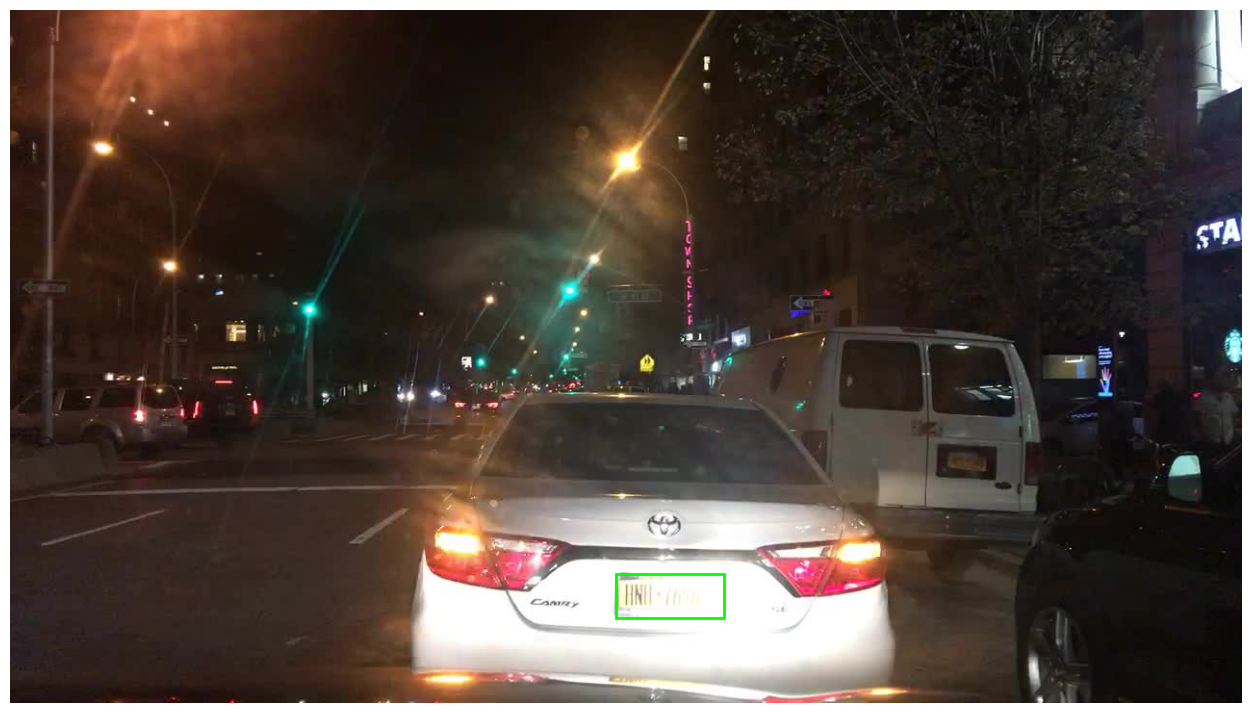

In [35]:
fig, ax = plt.subplots(figsize=(16, 9))

ax.imshow(image)

for annotation in annotations:

    class_id, *box = annotation

    x1, y1, x2, y2 = yolo_to_xyxy(box, w, h)

    rectangle = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        edgecolor="lime",
        facecolor="none",
        linewidth=2
    )

    ax.add_patch(rectangle)

ax.axis("off")
plt.show()

### Count annotated licence plates

In [36]:
records = []

for path in label_files:

    lines = path.read_text().strip().splitlines()

    records.append({
        "image_id": path.stem,
        "split": path.parent.name,
        "plate_count": len(lines)
    })

annotation_stats = pd.DataFrame(records)

annotation_stats.head()

,image_id,split,plate_count
0,d22dc344-46571c2f,Test,1
1,d2f3e8c3-c04896c8,Test,1
2,d6087157-fc728703,Test,2
3,dccfcce5-ad496380,Test,1
4,f85bbdf5-4a8e3a62,Test,2


In [37]:
annotation_stats.groupby("split").agg(
    label_files=("image_id", "count"),
    total_plates=("plate_count", "sum"),
    average_plates=("plate_count", "mean"),
    max_plates=("plate_count", "max")
)

,label_files,total_plates,average_plates,max_plates
split,,,,
Test,5,7,1.40,2
Train,25,48,1.92,4
Validation,2,3,1.50,2


In [38]:
annotation_stats["plate_count"].sum()

np.int64(58)

## Dataset Validation and Training Preparation

In [14]:
yolo_dir = poc_dir / "yolo_dataset"

In [15]:
import yaml

dataset_config = {
    "path": str(yolo_dir.resolve()),
    "train": "images/Train",
    "val": "images/Validation",
    "test": "images/Test",
    "names": {
        0: "license_plate"
    }
}

with open(yolo_dir / "data.yaml", "w") as f:
    yaml.safe_dump(dataset_config, f, sort_keys=False)

print((yolo_dir / "data.yaml").read_text())

path: C:\Users\aarish.tickoo\workspace\traffic-pii-masking\data\poc\yolo_dataset
train: images/Train
val: images/Validation
test: images/Test
names:
  0: license_plate



## Licence Plate Detection — Model Training

In [16]:
%pip install ultralytics

  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.5 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.5 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.5 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.5 MB ? eta -:--:--
   -------------- ------------------------- 0.5/1.5 MB 266.4 kB/s eta 0:00:04
   -------------- ------------------------- 0.5/1.5 MB 266.4 kB/s eta 0:00:04
   -------------- -----------

In [17]:
import torch
from ultralytics import YOLO

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\aarish.tickoo\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch version: 2.15.0+cpu
CUDA available: False


In [18]:
model = YOLO("yolo11n.pt")

In [19]:
results = model.train(
    data=str(yolo_dir / "data.yaml"),
    epochs=10,
    imgsz=640,
    batch=4,
    device="cpu",
    workers=0,
    seed=42,
    project=str(poc_dir / "runs"),
    name="license_plate_baseline"
)

Ultralytics 8.4.218  Python-3.12.0 torch-2.15.0+cpu CPU (12th Gen Intel Core i3-1215U)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=c:\Users\aarish.tickoo\workspace\traffic-pii-masking\data\poc\yolo_dataset\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name

## Trained Model Evaluation and Inference

In [20]:
run_dir = Path(results.save_dir)

best_model_path = run_dir / "weights" / "best.pt"

assert best_model_path.exists()

trained_model = YOLO(str(best_model_path))

print("Model loaded successfully")
print(trained_model.names)

# demonstrating that a saved model can be loaded independently of the original training process.

Model loaded successfully
{0: 'license_plate'}


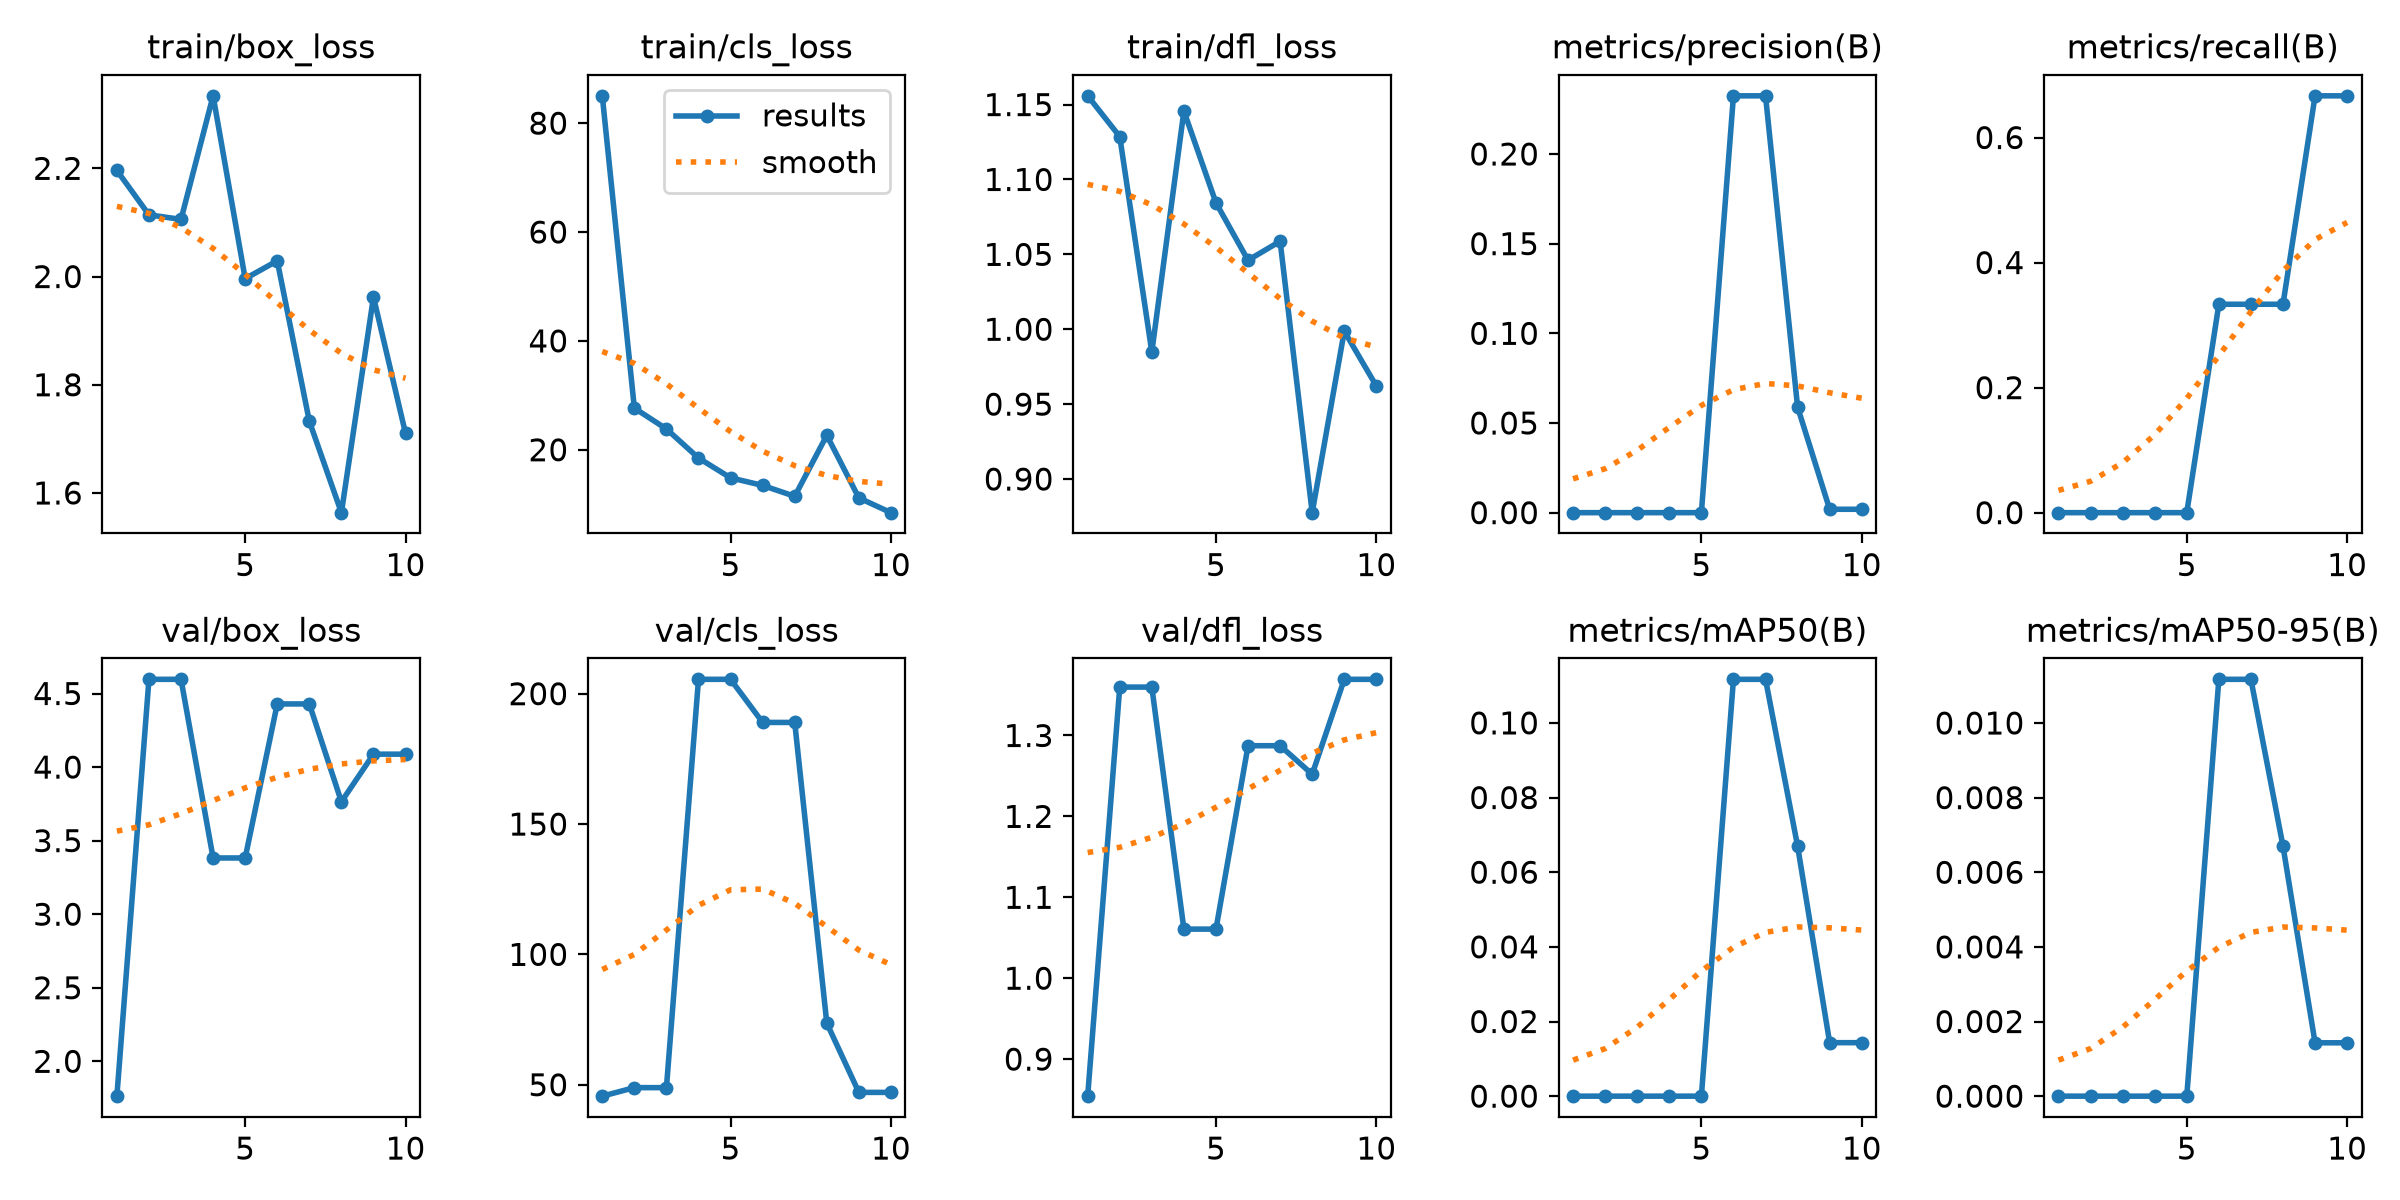

In [21]:
display(Image.open(run_dir / "results.png"))

In [22]:
test_metrics = trained_model.val(
    data=str(yolo_dir / "data.yaml"),
    split="test",
    device="cpu",
    workers=0,
    imgsz=640
)

Ultralytics 8.4.218  Python-3.12.0 torch-2.15.0+cpu CPU (12th Gen Intel Core i3-1215U)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
WARNING val: Slow image access detected (ping: 0.2±0.1 ms, read: 5.3±1.8 MB/s, size: 64.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning C:\Users\aarish.tickoo\workspace\traffic-pii-masking\data\poc\yolo_dataset\labels\Test... 5 images, 5 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 10/10 179.6it/s 0.1s
val: New cache created: C:\Users\aarish.tickoo\workspace\traffic-pii-masking\data\poc\yolo_dataset\labels\Test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.4s/it 1.4s
                   all         10          7       0.18      0.429      0.161     0.0725
Speed: 1.9ms preprocess, 73.5ms inference, 0.0ms loss, 46.4ms postprocess per image
Resul

In [23]:
print("Precision:", test_metrics.box.mp)
print("Recall:", test_metrics.box.mr)
print("mAP50:", test_metrics.box.map50)
print("mAP50-95:", test_metrics.box.map)

Precision: 0.18006770514009637
Recall: 0.42857142857142855
mAP50: 0.1612019230769231
mAP50-95: 0.07246634615384616


Perform inference on a single unseen image

In [24]:
test_images = sorted(
    (yolo_dir / "images" / "Test").glob("*.jpg")
)

print("Total test images:", len(test_images))

Total test images: 10


In [25]:
image_path = next(
    path for path in test_images
    if (
        yolo_dir / "labels" / "Test" / f"{path.stem}.txt"
    ).exists()
)

print(image_path.name)

d22dc344-46571c2f.jpg


In [26]:
predictions = trained_model.predict(
    source=str(image_path),
    conf=0.10,
    imgsz=640,
    device="cpu"
)


image 1/1 c:\Users\aarish.tickoo\workspace\traffic-pii-masking\data\poc\yolo_dataset\images\Test\d22dc344-46571c2f.jpg: 384x640 35 license_plates, 194.8ms
Speed: 8.7ms preprocess, 194.8ms inference, 5.3ms postprocess per image at shape (1, 3, 384, 640)


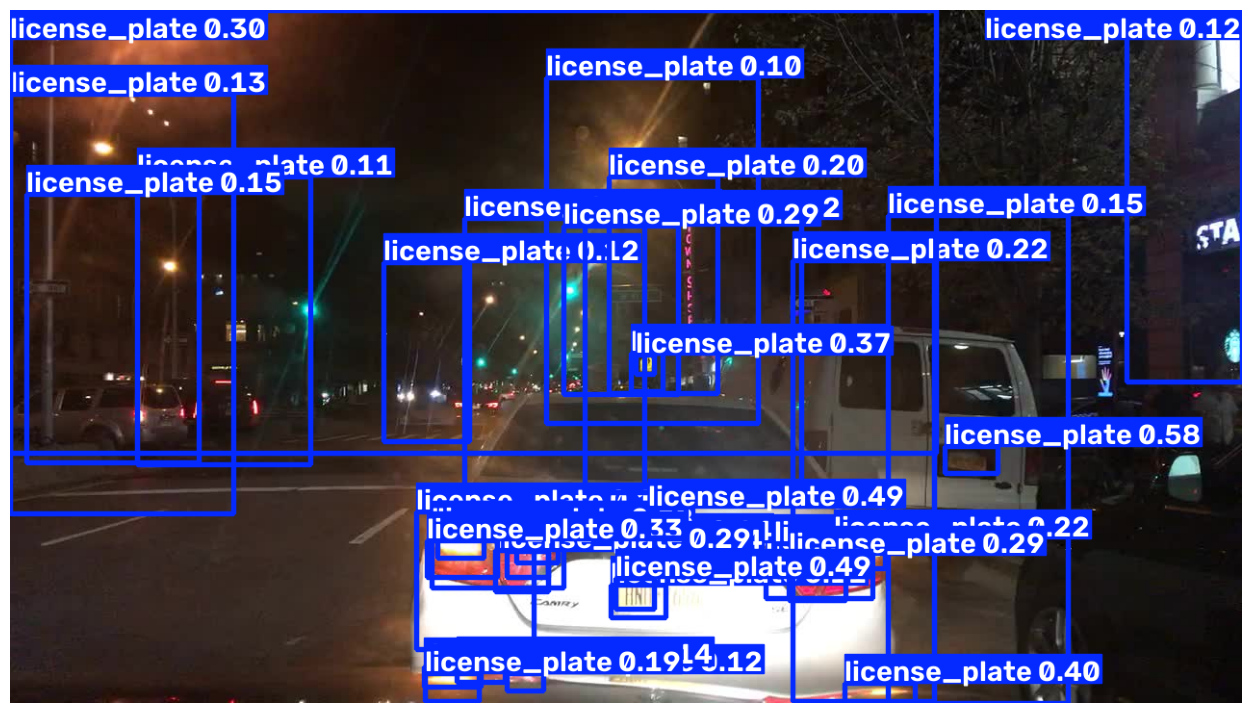

In [27]:
predicted_image = predictions[0].plot()

plt.figure(figsize=(16, 9))
plt.imshow(predicted_image[:, :, ::-1])
plt.axis("off")
plt.show()

In [ ]:
### haha this is clearly very bad for now. But it is okay for now. The POC works.  

In [28]:
prediction = predictions[0]

boxes = prediction.boxes

print("Detected plates:", len(boxes))

print("Bounding boxes:")
print(boxes.xyxy)

print("Confidence scores:")
print(boxes.conf)

print("Class IDs:")
print(boxes.cls)

Detected plates: 35
Bounding boxes:
tensor([[ 971.1954,  453.9410, 1026.3303,  481.1055],
        [ 629.8134,  590.4484,  669.8873,  622.5619],
        [ 663.3265,  517.8586,  702.1794,  548.3600],
        [ 867.9291,  699.6276,  940.1235,  720.0000],
        [ 650.1793,  358.6758,  669.2527,  378.7684],
        [ 433.9729,  551.0347,  506.6223,  589.1731],
        [   0.0000,    0.0000,  962.3356,  460.7852],
        [ 809.9137,  566.1494,  868.5990,  613.0452],
        [ 575.5916,  224.3564,  694.8859,  399.0452],
        [ 504.4696,  561.0446,  559.0013,  604.3444],
        [ 444.4883,  540.8116,  492.2603,  569.9625],
        [ 856.4622,  549.7676,  909.3179,  580.9630],
        [ 813.0629,  260.7791,  960.1124,  718.8842],
        [ 622.4581,  173.3152,  735.8653,  398.3141],
        [ 645.3882,  356.4296,  678.4050,  396.5995],
        [ 431.8711,  689.5175,  487.9622,  718.0033],
        [ 430.1259,  682.7271,  489.9117,  703.4817],
        [ 794.8658,  554.7209,  854.6842,  575

### Masking the predicted bounding boxes.

In [ ]:
# Implement a reusable masking function
import cv2
import numpy as np

def mask_license_plates(image, boxes):
    masked_image = image.copy()
    height, width = image.shape[:2]

    for box in boxes:
        x1, y1, x2, y2 = map(int, box)

        x1 = max(0, min(x1, width))
        x2 = max(0, min(x2, width))
        y1 = max(0, min(y1, height))
        y2 = max(0, min(y2, height))

        if x2 <= x1 or y2 <= y1:
            continue

        masked_image[y1:y2, x1:x2] = 0

    return masked_image

In [ ]:
# Combine inference and masking
def anonymize_image(image_path, model, conf=0.25):
    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Unable to read image: {image_path}")

    prediction = model.predict(
        source=image,
        conf=conf,
        device="cpu",
        verbose=False
    )[0]

    boxes = prediction.boxes.xyxy.cpu().numpy()

    masked_image = mask_license_plates(image, boxes)

    return image, masked_image, prediction

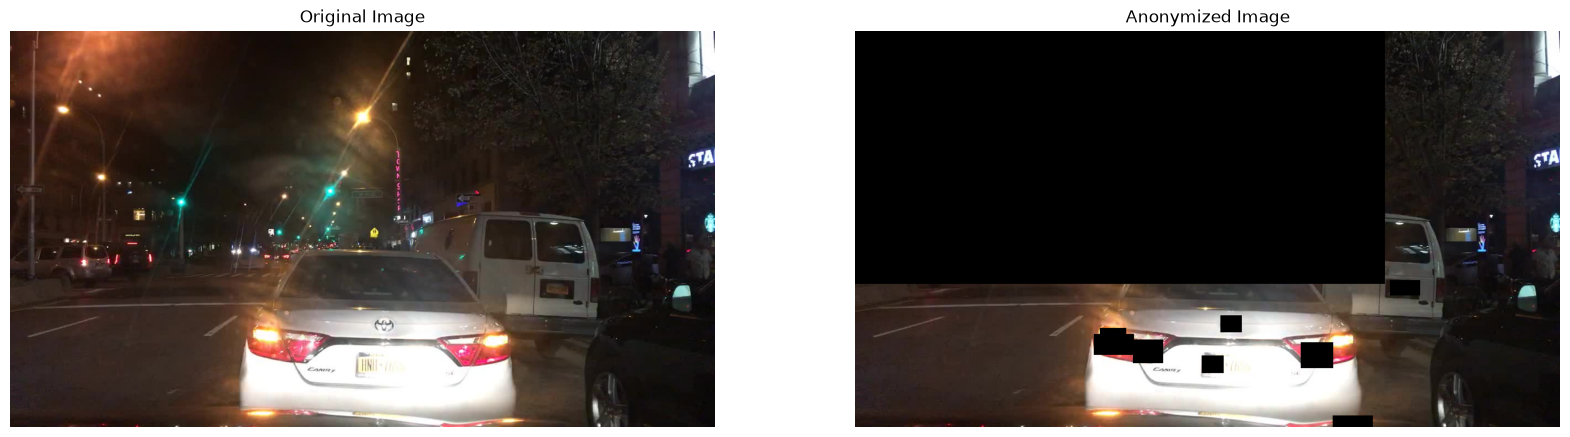

In [31]:
original, masked, prediction = anonymize_image(
    image_path,
    trained_model
)

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

axes[0].imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original Image")

axes[1].imshow(cv2.cvtColor(masked, cv2.COLOR_BGR2RGB))
axes[1].set_title("Anonymized Image")

for ax in axes:
    ax.axis("off")

plt.show()

In [32]:
output_dir = poc_dir / "anonymized"
output_dir.mkdir(parents=True, exist_ok=True)

cv2.imwrite(
    str(output_dir / image_path.name),
    masked
)

True

| Potential problem | Impact |
|---|---|
| Only 35 training images | Insufficient visual examples |
| Only 48 annotated training plates | Limited supervision |
| Extremely small licence plates | Difficult feature extraction |
| Resizing images to 640 | Further loss of small-object detail |
| Missing annotations | Potentially contradictory training signals |
| Only 10 epochs | Potential undertraining |
| Only 3 validation plate instances | Unreliable checkpoint selection |
| Low inference confidence threshold | Excessive false positives |

In [ ]:
# End of notebook 